# SEM in transversely isotropic media in 3-D

`ElasticVTISEM3D` and `ElasticTTISEM3D` (Hex8), and their `...Deformed` versions on the Hex27
mesh of a topography, are the 3-D velocity-stress SEM in a transversely isotropic medium. The
models are the vertical velocities `vp`, `vs`, the density `rho`, Thomsen's `epsilon`, `delta`
and `gamma`, and for the tilted medium the tilt `theta` and azimuth `phi` of the symmetry axis
(radians) -- the parameters and the Bond rotation of the FD `ElasticTTISG3D`. Only the stress
update changes: all 21 stiffnesses act on the six strain rates, and the time loop, the C-PML,
the free surface and the gradients are those of `ElasticVSSEM3D`.

1. Wavefronts of a point force in an isotropic, a VTI and a tilted medium.
2. Shear-wave splitting: a shear wave crossing a medium whose symmetry axis is horizontal.
3. Under a topography: the deformed classes on a flat surface and under a hill.

About ten minutes on a GPU, most of it the 5 m grids of sections 1 and 3.

In [1]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.propagator import EagerOptions, Full
from sweep.sem import ElasticTTISEM3D, ElasticVSSEM3D, ElasticVTISEM3D, PropSEM

DEV = "cuda" if torch.cuda.is_available() else "cpu"   # eager: the snapshots need it
F32, F64 = torch.float32, torch.float64                  # snapshots in fp32, records in fp64
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
print(f"device {DEV}")

device cuda


## 1. Wavefronts

A vertical force near the centre of an 820 m cube of 5 m cells, with a C-PML on all six sides:
the vertical velocity `vz` 0.1 s after the peak of the wavelet, on the vertical plane and on the
horizontal plane through the force, computed in single precision.
The VTI medium has `epsilon = 0.25`, `delta = 0.05`, `gamma = 0.15`; the tilted one is the same
medium with its axis tilted by 40 degrees toward the azimuth 30 degrees. The amplitude is drawn as
`sign(v) sqrt(|v| / max)`, so that the weaker P fronts show beside the shear ones. The fastest wave
travels along the plane of isotropy at `vp sqrt(1 + 2 epsilon)`, which sets the time step.

In [2]:
DH, NO, F0, DELAY = 5.0, 4, 18.0, 0.06
SHAPE, ABCN, DT = (165, 165, 165), 32, 2.5e-4
VP, VS, RHO = 2000.0, 1000.0, 2000.0
ANISO = (0.25, 0.05, 0.15)                                # epsilon, delta, gamma
TILT = (np.radians(40.0), np.radians(30.0))               # theta, phi
SNAP = 640                                                # step: 0.16 s, 0.1 s after the peak
NT = SNAP + 1
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - DELAY)) ** 2
wav = torch.from_numpy((1 - 2 * a) * np.exp(-a)).to(DEV, F32)
C0 = 82                                                   # the middle of an element, 410 m
src = np.array([[C0, C0, C0]], dtype=float)               # (ix, iy, iz) grid indices
rec = np.array([[[C0, C0, 20.0]]])
print(f"vp sqrt(1 + 2 epsilon) = {VP * np.sqrt(1 + 2 * ANISO[0]):.0f} m/s")


def snapshot(eq, extra=()):
    p = PropSEM(eq, shape=SHAPE, dh=DH, dt=DT, n_order=NO, abcn=ABCN, free_surface=False,
                f_dominant=F0, dev=DEV, dtype=F32, impl="eager", memory=Full(),
                eager_options=EagerOptions(use_compile=False), source_type=["vz"],
                receiver_type=["vz"])
    ms = [torch.full(SHAPE, float(v), dtype=F32, device=DEV) for v in (VP, VS, RHO) + extra]
    t0 = time.time()
    with torch.no_grad():
        _, snaps = p(wav, src, rec, models=ms, return_wavefield=True, snapshot_times=[SNAP])
    print(f"{eq.__name__}: {time.time() - t0:.1f} s")
    v = snaps[0, 0, 0, 0].numpy()                         # (nz, ny, nx) with the layer
    pz, py, px = ((n - s) // 2 for n, s in zip(v.shape, SHAPE))
    return v[pz:pz + SHAPE[0], py:py + SHAPE[1], px:px + SHAPE[2]]


iso = snapshot(ElasticVSSEM3D)
vti = snapshot(ElasticVTISEM3D, ANISO)
tti = snapshot(ElasticTTISEM3D, ANISO + TILT)

vp sqrt(1 + 2 epsilon) = 2449 m/s


ElasticVSSEM3D: 58.0 s


ElasticVTISEM3D: 59.6 s


ElasticTTISEM3D: 77.6 s


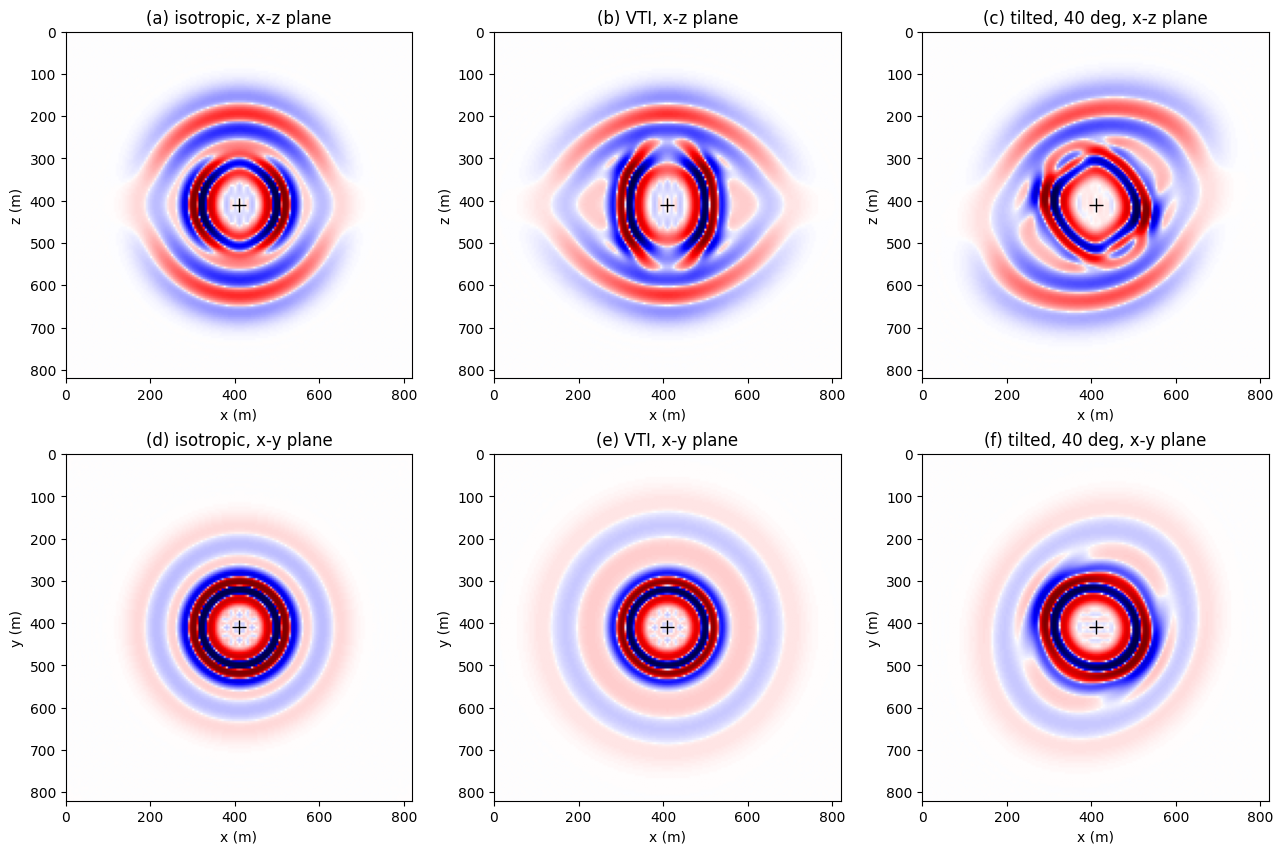

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(13, 8.6))
ext = [0, (SHAPE[2] - 1) * DH, (SHAPE[0] - 1) * DH, 0]
peak = np.abs(iso).max()
gain = lambda v: np.sign(v) * np.sqrt(np.abs(v) / peak)     # the weaker P fronts show too
for j, (v, name) in enumerate(((iso, "isotropic"), (vti, "VTI"), (tti, "tilted, 40 deg"))):
    for i, (sl, lab) in enumerate(((v[:, C0, :], "x-z plane"), (v[C0, :, :], "x-y plane"))):
        a_ = ax[i, j]
        a_.imshow(gain(sl), cmap="seismic", vmin=-0.8, vmax=0.8, extent=ext)
        a_.set_title(f"({'abcdef'[3 * i + j]}) {name}, {lab}")
        a_.set_xlabel("x (m)")
        a_.set_ylabel("z (m)" if i == 0 else "y (m)")
        a_.plot(C0 * DH, C0 * DH, "k+", ms=10)
fig.tight_layout()
plt.show()

In the isotropic medium (a, d) the P and shear fronts are circles. In the VTI medium (b, e)
the P front reaches farther sideways than up and down, by `sqrt(1 + 2 epsilon)` = 1.22 (about 245
against 200 m here), and since `delta` is smaller than `epsilon` it is not an ellipse: between
the axes it lags the ellipse through those two extents. The horizontal plane keeps the circular
symmetry of a vertical axis (e). Tilting the axis turns the pattern (c): the P front is longest
across the axis, in the plane of isotropy. In the horizontal plane (f) the fronts lose the
circular symmetry; the P front reaches farthest across the azimuth of the tilt, the horizontal
direction that lies in the plane of isotropy.

## 2. Shear-wave splitting

With the symmetry axis horizontal (`theta = 90` degrees, here along x), a shear wave travelling
vertically splits: polarized along the axis it travels at `vs`, polarized across it at
`vs sqrt(1 + 2 gamma)`. A horizontal force at 45 degrees between x and y, 400 m under a free
surface, sends a shear wave up to a receiver right above; in the isotropic medium its two
horizontal components are the same pulse, in the medium with the horizontal axis `vy` (across
the axis) leads `vx` (along it) by `400 (1/vs - 1/(vs sqrt(1 + 2 gamma)))`.

In [4]:
SHAPE2, DT2, NT2 = (49, 41, 41), 5e-4, 1100                # 480 x 400 x 400 m, 0.55 s
DH2, ABCN2 = 10.0, 16                                     # 10 m cells here
GAMMA = 0.15
t2 = np.arange(NT2) * DT2
a2 = (np.pi * F0 * (t2 - DELAY)) ** 2
wav2 = torch.from_numpy((1 - 2 * a2) * np.exp(-a2)).to(DEV)
src2 = np.array([[20.0, 20.0, 40.0]])                     # 400 m deep
rec2 = np.array([[[20.0, 20.0, 0.0]]])                    # on the surface above


def split(eq, extra=(), **kw):
    p = PropSEM(eq, shape=SHAPE2, dh=DH2, dt=DT2, n_order=NO, abcn=ABCN2, free_surface=True,
                f_dominant=F0, dev=DEV, dtype=F64, impl="eager", memory=Full(),
                eager_options=EagerOptions(use_compile=False), source_type=["vx", "vy"],
                receiver_type=["vx", "vy"], **kw)
    ms = [torch.full(SHAPE2, float(v), dtype=F64, device=DEV) for v in (VP, VS, RHO) + extra]
    t0 = time.time()
    with torch.no_grad():
        out = p(wav2, src2, rec2, models=ms)[0, :, 0].cpu().numpy()
    print(f"{eq.__name__}: {time.time() - t0:.1f} s")
    return out


iso2 = split(ElasticVSSEM3D)
hti2 = split(ElasticTTISEM3D, (0.0, 0.0, GAMMA, np.pi / 2, 0.0))
dt_theory = 400.0 * (1 / VS - 1 / (VS * np.sqrt(1 + 2 * GAMMA)))
w = t2 > 0.3                                              # the shear wave's window
lag = lambda a, b: (np.argmax(np.abs(b[w])) - np.argmax(np.abs(a[w]))) * DT2
print(f"vx - vy delay: isotropic {lag(iso2[:, 1], iso2[:, 0]) * 1e3:.1f} ms, horizontal axis "
      f"{lag(hti2[:, 1], hti2[:, 0]) * 1e3:.1f} ms, expected {dt_theory * 1e3:.1f} ms")

ElasticVSSEM3D: 5.1 s


ElasticTTISEM3D: 5.5 s
vx - vy delay: isotropic 0.0 ms, horizontal axis 51.0 ms, expected 49.2 ms


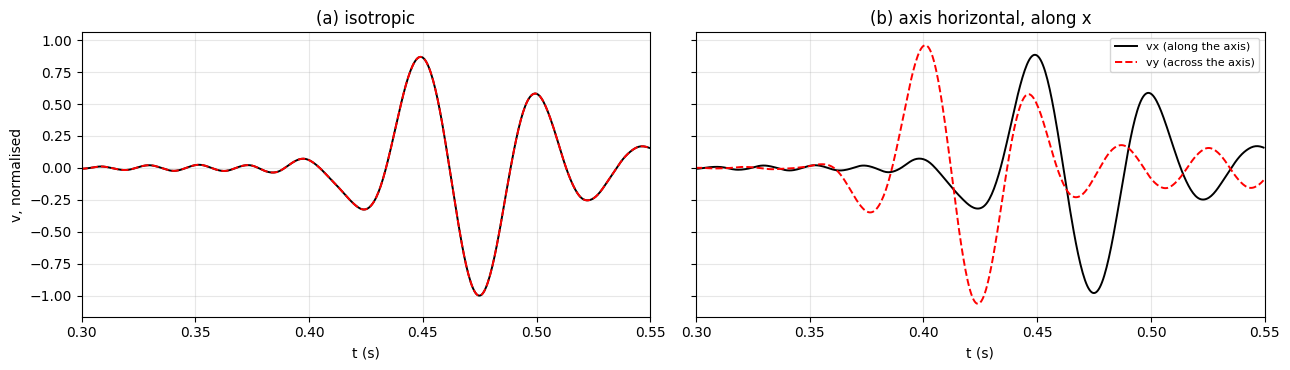

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
s = 1.0 / np.abs(iso2).max()
for a_, data, lab in zip(ax, (iso2, hti2), ("(a) isotropic", "(b) axis horizontal, along x")):
    a_.plot(t2, s * data[:, 0], "k", lw=1.4, label="vx (along the axis)")
    a_.plot(t2, s * data[:, 1], "r--", lw=1.4, label="vy (across the axis)")
    a_.set_title(lab)
    a_.set_xlabel("t (s)")
    a_.set_xlim(0.3, 0.55)
    a_.grid(alpha=0.3)
ax[0].set_ylabel("v, normalised")
ax[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

Both horizontal components of the isotropic record (a) are one pulse (the force is at 45
degrees). With the axis horizontal (b) the pulse splits into the fast shear wave on `vy`,
polarized across the axis, and the slow one on `vx`, polarized along it, separated by the delay
the two shear velocities give over the 400 m path, as printed above. Rotating the horizontal
components to find the fast direction and that delay is the usual measurement of shear-wave
splitting; with `gamma = 0` the two waves travel together, as in (a).

## 3. Under a topography

`ElasticVTISEM3DDeformed` and `ElasticTTISEM3DDeformed` take a topography of shape `(ny, nx)`,
as `AcousticSEM3DDeformed` does in [SEM basics · 7](../56_sem_3d/), and the mesh's element rows
follow it. The surface is free in the same way as the flat one: the weak form drops its
traction integral, whatever the stiffnesses. On a flat surface the deformed class runs the
discretization of the Hex8 class, so the splitting run of section 2 gives the same records.
Under a 100 m hill, a vertical force 310 m below the crest sends its waves up into the relief,
in the isotropic medium and in the tilted one of section 1. The panels show the vertical
velocity on the two vertical planes through the force, with the air above the surface left
white.

ElasticTTISEM3DDeformed: 11.4 s
flat surface, Hex27 against Hex8: relative L2 1.1e-14


ElasticVSSEM3DDeformed under the hill: 144.4 s


ElasticTTISEM3DDeformed under the hill: 165.9 s


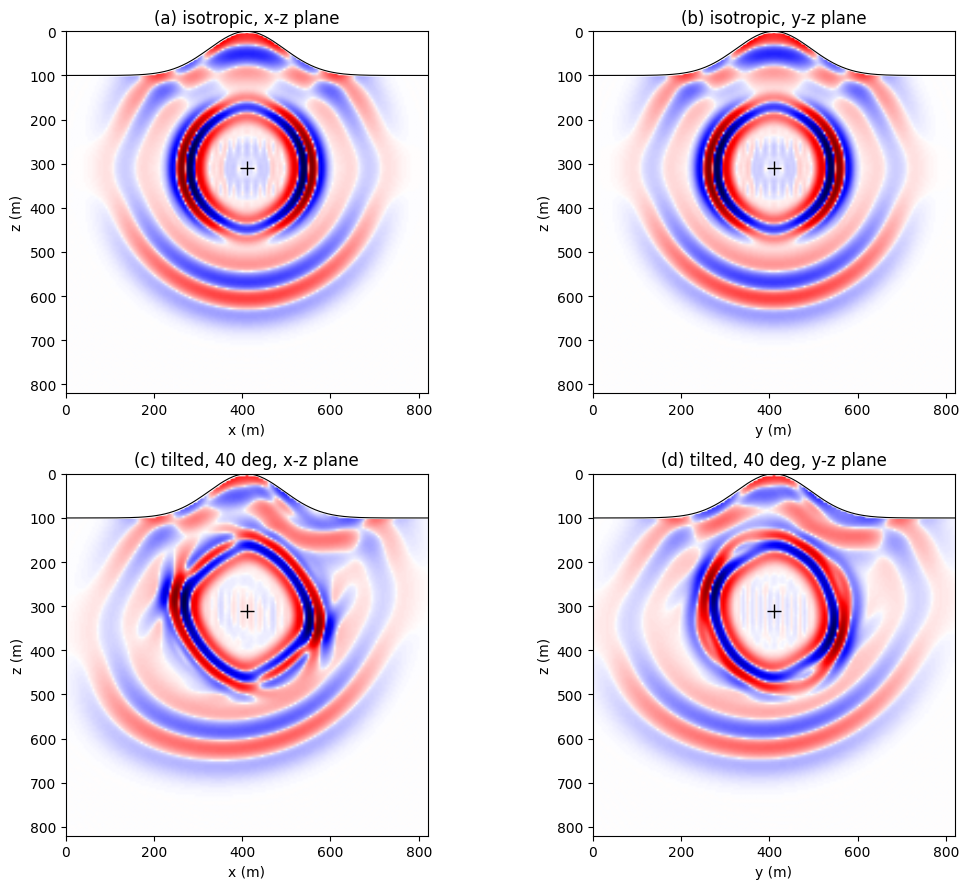

In [6]:
from sweep.sem import ElasticTTISEM3DDeformed, ElasticVSSEM3DDeformed

hti_flat = split(ElasticTTISEM3DDeformed, (0.0, 0.0, GAMMA, np.pi / 2, 0.0),
                 topography=np.zeros(SHAPE2[1:]))
print(f"flat surface, Hex27 against Hex8: relative L2 "
      f"{np.linalg.norm(hti_flat - hti2) / np.linalg.norm(hti2):.1e}")

SHAPE3, SNAP3 = SHAPE, 800                                 # 0.2 s, 0.14 s after the peak
yy, xx = np.meshgrid(np.arange(SHAPE3[1]), np.arange(SHAPE3[2]), indexing="ij")
topo = 20.0 * (1.0 - np.exp(-((xx - C0) ** 2 + (yy - C0) ** 2) / 24.0 ** 2))   # rows: crest 0, plain 20
t3 = np.arange(SNAP3 + 1) * DT
a3 = (np.pi * F0 * (t3 - DELAY)) ** 2
wav3 = torch.from_numpy((1 - 2 * a3) * np.exp(-a3)).to(DEV, F32)
src3 = np.array([[C0, C0, 62.0]])                          # 310 m below the crest


def under_hill(eq, extra=()):
    p = PropSEM(eq, shape=SHAPE3, dh=DH, dt=DT, n_order=NO, abcn=ABCN, free_surface=True,
                topography=topo, f_dominant=F0, dev=DEV, dtype=F32, impl="eager", memory=Full(),
                eager_options=EagerOptions(use_compile=False), source_type=["vz"],
                receiver_type=["vz"])
    ms = [torch.full(SHAPE3, float(v), dtype=F32, device=DEV) for v in (VP, VS, RHO) + extra]
    t0 = time.time()
    with torch.no_grad():
        _, snaps = p(wav3, src3, np.array([[[C0, C0, 24.0]]]), models=ms,
                     return_wavefield=True, snapshot_times=[SNAP3])
    print(f"{eq.__name__} under the hill: {time.time() - t0:.1f} s")
    v = snaps[0, 0, 0, 0].numpy()                         # the layer below and at the sides
    py, px = ((n - s) // 2 for n, s in zip(v.shape[1:], SHAPE3[1:]))
    return v[:SHAPE3[0], py:py + SHAPE3[1], px:px + SHAPE3[2]]


hill = {"isotropic": under_hill(ElasticVSSEM3DDeformed),
        "tilted, 40 deg": under_hill(ElasticTTISEM3DDeformed, ANISO + TILT)}

fig, ax = plt.subplots(2, 2, figsize=(11, 9))
peak = np.percentile(np.abs(np.stack(list(hill.values()))), 99.9)   # one scale for all
for i, (name, v) in enumerate(hill.items()):
    for j, (sl, surf, lab) in enumerate(((v[:, C0, :], topo[C0, :], "x-z plane"),
                                         (v[:, :, C0], topo[:, C0], "y-z plane"))):
        img = np.sign(sl) * np.sqrt(np.abs(sl) / peak)    # zero above the surface
        a_ = ax[i, j]
        a_.imshow(img, cmap="seismic", vmin=-1.0, vmax=1.0, extent=ext, interpolation="bilinear")
        a_.fill_between(np.arange(SHAPE3[2]) * DH, 0.0, surf * DH, color="w")   # the air
        a_.plot(np.arange(SHAPE3[2]) * DH, surf * DH, "k", lw=0.8)
        a_.plot(C0 * DH, 62.0 * DH, "k+", ms=10)
        a_.set_title(f"({'abcd'[2 * i + j]}) {name}, {lab}")
        a_.set_xlabel("x (m)" if j == 0 else "y (m)")
        a_.set_ylabel("z (m)")
fig.tight_layout()
plt.show()

On the flat surface the deformed class gives the records of the Hex8 class to round-off. Under
the hill, 0.14 s after the peak, the P front has reached the surface and fills the relief, and
the shear front is still around the force. In the isotropic medium (a, b) the shear front is a
circle on both planes; in the tilted medium (c, d) it is turned and squared off as in section 1,
and differently on the two planes, since the axis tilts toward the azimuth 30 degrees. The free
surface is the same for both media, so the anisotropic classes take a curved free surface as the
isotropic ones do.

---

<p><strong>Download this notebook</strong> &mdash; <a href="60_sem_tti3d.ipynb" download><code>60_sem_tti3d.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/60_sem_tti3d.ipynb">view on GitHub</a></p>